In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

In [2]:
from sklearn.datasets import make_blobs

In [36]:
X,y=make_blobs(n_samples=1000,centers=3,n_features=2)

In [37]:
X

array([[ 8.74989545, -6.39806825],
       [ 8.83622336, -6.28784469],
       [ 2.02341242,  5.48927878],
       ...,
       [-3.05603564,  8.07182108],
       [ 7.52442287, -6.52862747],
       [ 4.11011077,  7.06231642]], shape=(1000, 2))

In [38]:
y

array([2, 2, 0, 1, 0, 0, 0, 2, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 2, 1, 1,
       0, 2, 1, 0, 2, 1, 1, 2, 0, 0, 2, 2, 0, 0, 1, 2, 1, 2, 1, 2, 0, 2,
       2, 1, 1, 2, 0, 0, 1, 0, 2, 2, 2, 0, 2, 2, 1, 1, 2, 1, 0, 2, 2, 2,
       1, 1, 1, 2, 1, 1, 2, 0, 2, 0, 0, 2, 1, 1, 2, 2, 1, 0, 1, 2, 2, 0,
       2, 0, 0, 2, 2, 0, 0, 1, 2, 2, 1, 0, 0, 1, 1, 0, 0, 1, 2, 2, 0, 1,
       2, 1, 0, 1, 1, 2, 2, 1, 2, 1, 2, 2, 0, 1, 0, 1, 1, 1, 1, 2, 2, 0,
       1, 1, 0, 0, 1, 2, 2, 1, 1, 0, 2, 1, 0, 1, 1, 2, 0, 2, 2, 1, 1, 2,
       2, 2, 0, 1, 2, 0, 1, 1, 0, 0, 2, 0, 1, 1, 0, 0, 1, 1, 2, 2, 2, 0,
       0, 2, 2, 1, 1, 0, 2, 2, 0, 1, 2, 1, 0, 0, 0, 1, 0, 1, 2, 0, 2, 1,
       1, 2, 1, 2, 0, 0, 1, 0, 1, 1, 0, 2, 1, 1, 1, 0, 2, 1, 2, 2, 0, 0,
       0, 1, 2, 1, 0, 1, 1, 1, 2, 0, 1, 1, 2, 1, 1, 0, 2, 1, 1, 2, 0, 0,
       0, 2, 1, 1, 1, 0, 2, 1, 1, 0, 0, 0, 2, 2, 1, 1, 1, 2, 2, 0, 2, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 2, 0, 0, 0, 2, 1, 0, 0, 0, 0, 1,
       0, 2, 1, 2, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1,

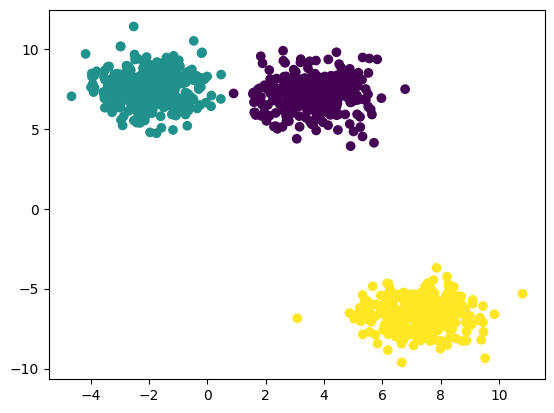

In [39]:
plt.scatter(X[:,0],X[:,1],c=y)

In [40]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.33,random_state=42)

In [41]:
## Standardization
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()


In [42]:
X_train_scaled=ss.fit_transform(X_train)
X_test_scaled=ss.transform(X_test)

In [43]:
from sklearn.cluster import KMeans

In [44]:
## Elbow Method to select the K Value
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,init="k-means++")
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

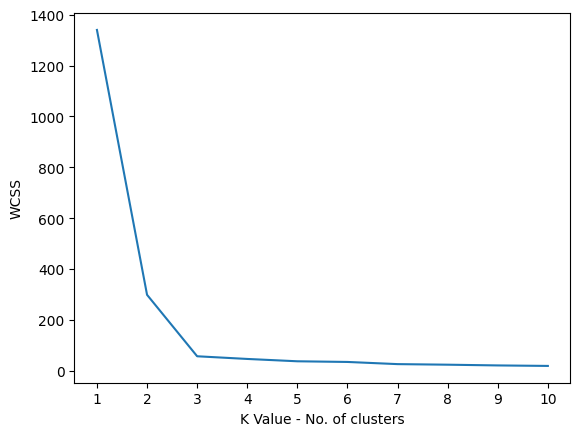

In [45]:
## plot elbow curve
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel("K Value - No. of clusters")
plt.ylabel("WCSS")
plt.show()

In [46]:
kmeans=KMeans(n_clusters=3,init="k-means++")

In [47]:
kmeans.fit_predict(X_train_scaled)

array([1, 2, 0, 0, 1, 2, 0, 0, 1, 2, 2, 2, 1, 2, 2, 0, 0, 2, 0, 0, 0, 2,
       1, 1, 2, 0, 2, 1, 1, 0, 2, 0, 0, 1, 1, 2, 1, 2, 1, 1, 0, 0, 2, 1,
       0, 1, 1, 0, 1, 2, 2, 2, 0, 2, 0, 0, 2, 2, 1, 0, 2, 1, 0, 0, 0, 1,
       2, 2, 0, 2, 2, 2, 1, 2, 2, 1, 0, 1, 0, 2, 0, 1, 2, 0, 1, 2, 2, 0,
       2, 2, 0, 0, 0, 0, 1, 2, 0, 2, 2, 0, 2, 0, 2, 2, 0, 0, 1, 0, 0, 2,
       2, 1, 0, 0, 1, 0, 0, 0, 2, 0, 1, 1, 0, 0, 1, 1, 2, 0, 2, 2, 1, 2,
       0, 2, 0, 0, 2, 1, 1, 0, 0, 1, 2, 0, 1, 2, 1, 1, 2, 1, 0, 0, 2, 1,
       2, 1, 0, 0, 2, 1, 1, 0, 0, 0, 2, 1, 0, 1, 0, 0, 1, 1, 2, 2, 0, 2,
       2, 0, 1, 0, 2, 0, 2, 0, 2, 0, 1, 2, 2, 0, 0, 2, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 2, 1, 0, 1, 1, 1, 0, 1, 2, 0, 0, 1, 1, 2, 2, 1, 0, 2, 2,
       1, 1, 2, 1, 0, 1, 0, 0, 2, 1, 0, 0, 0, 1, 2, 0, 0, 1, 0, 1, 1, 0,
       0, 2, 2, 0, 1, 0, 2, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 0, 2, 2, 0, 1,
       2, 1, 1, 1, 0, 2, 0, 2, 1, 1, 1, 1, 0, 1, 0, 1, 2, 1, 2, 1, 0, 0,
       2, 0, 2, 2, 0, 2, 0, 2, 0, 0, 0, 0, 0, 1, 2,

In [48]:
y_pred=kmeans.predict(X_test_scaled)

In [49]:
y_pred

array([0, 0, 0, 2, 0, 2, 2, 1, 2, 2, 0, 0, 1, 0, 2, 1, 2, 2, 0, 0, 2, 1,
       0, 1, 2, 0, 2, 0, 1, 1, 1, 2, 1, 2, 1, 2, 1, 0, 1, 2, 2, 1, 1, 0,
       2, 0, 2, 2, 0, 2, 0, 2, 0, 1, 1, 0, 0, 0, 2, 1, 2, 1, 2, 1, 2, 2,
       2, 1, 2, 1, 1, 0, 1, 0, 0, 1, 0, 1, 2, 0, 1, 2, 1, 2, 2, 1, 1, 1,
       1, 0, 2, 1, 2, 0, 1, 0, 1, 1, 1, 0, 2, 1, 2, 2, 0, 2, 1, 0, 0, 1,
       2, 2, 1, 2, 1, 2, 0, 0, 2, 0, 1, 2, 2, 1, 2, 0, 0, 2, 0, 2, 1, 0,
       2, 0, 1, 0, 1, 2, 0, 1, 1, 0, 0, 0, 1, 1, 0, 2, 1, 2, 0, 1, 2, 2,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 2, 0, 2, 2, 0, 1, 1, 1, 2, 1, 1, 0, 1,
       1, 1, 1, 2, 1, 0, 0, 1, 0, 1, 0, 2, 1, 1, 0, 2, 1, 1, 0, 2, 1, 0,
       0, 2, 1, 0, 2, 2, 1, 1, 0, 2, 2, 1, 1, 0, 1, 2, 0, 2, 0, 2, 2, 0,
       0, 2, 0, 0, 1, 0, 0, 2, 2, 2, 1, 1, 1, 0, 1, 0, 2, 0, 0, 0, 2, 2,
       0, 1, 0, 2, 1, 1, 2, 0, 2, 2, 1, 1, 1, 0, 0, 0, 2, 0, 0, 2, 1, 0,
       2, 2, 0, 2, 1, 0, 1, 1, 2, 2, 1, 0, 1, 1, 1, 2, 2, 1, 1, 0, 2, 2,
       2, 2, 2, 2, 1, 1, 1, 2, 1, 2, 0, 0, 1, 1, 0,

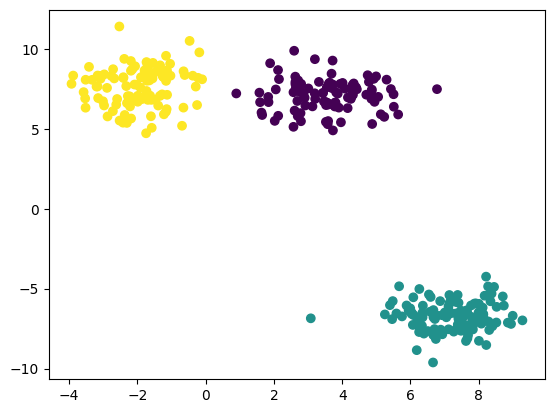

In [50]:
plt.scatter(X_test[:,0],X_test[:,1],c=y_pred)

In [ ]:
## Validating the K Value
## Knee locater
## Silhoutee Scoring

In [53]:
## Kneelocater
!pip install kneed

In [55]:
from kneed import KneeLocator

In [56]:
k1=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")

In [57]:
k1.elbow

np.int64(3)

In [58]:
## Silhoutee Scoring
from sklearn.metrics import silhouette_score

In [59]:
silhouette_coefficients=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,init="k-means++")
    kmeans.fit(X_train_scaled)
    score=silhouette_score(X_train_scaled,kmeans.labels_)
    silhouette_coefficients.append(score)

In [60]:
silhouette_coefficients

[0.723418714577918,
 0.7751016502581387,
 0.6587770468779591,
 0.6194861339099825,
 0.41630915121052975,
 0.4660769237286221,
 0.3685231632343467,
 0.3496888952217769,
 0.3640532062801061]

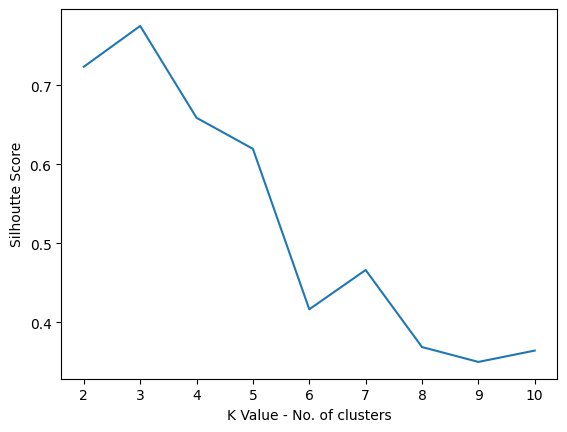

In [64]:
## plot elbow curve
plt.plot(range(2,11),silhouette_coefficients)
plt.xticks(range(2,11))
plt.xlabel("K Value - No. of clusters")
plt.ylabel("Silhoutte Score")
plt.show()